In [1]:
# correlation
# Reads: ../data/clean_joined.csv 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:

sns.set_theme(style="whitegrid")

In [3]:
# loading the joined table I made in the join notebook
df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
print("Rows:", len(df), "| Countries:", df["Entity"].nunique(), "| Years:", df["Year"].min(), "to", df["Year"].max())


Rows: 10429 | Countries: 163 | Years: 1950 to 2022


In [4]:
# I measure how strongly wealth goes with each health measure
# Pearson looks for a straight line, 
# # Spearman looks at ranks (it copes with curves)
pairs = [
    ("log_gdp", "life_exp", "log GDP vs life expectancy"),
    ("log_gdp", "child_mort", "log GDP vs child mortality"),
    ("log_gdp", "log_child_mort", "log GDP vs log child mortality"),
    ("gdp_pc", "life_exp", "raw GDP vs life expectancy"),
]
rows = []
for x, y, label in pairs:
    r, p_r = stats.pearsonr(df[x], df[y])
    rho, p_s = stats.spearmanr(df[x], df[y])
    rows.append({"Pair": label, "Pearson r": round(r, 3), "r squared": round(r**2, 3),
                 "Spearman rho": round(rho, 3),
                 "p-value": "< 0.001" if p_r < 0.001 else f"{p_r:.3f}"})
results = pd.DataFrame(rows)
print("\nCORRELATIONS (all country-years, 1950 onward)")
display(results)


CORRELATIONS (all country-years, 1950 onward)


,Pair,Pearson r,r squared,Spearman rho,p-value
0,log GDP vs life expectancy,0.830,0.689,0.861,< 0.001
1,log GDP vs child mortality,-0.741,0.549,-0.857,< 0.001
2,log GDP vs log child mortality,-0.854,0.730,-0.857,< 0.001
3,raw GDP vs life expectancy,0.623,0.388,0.861,< 0.001


In [5]:
# keep the two main numbers to use in my chart titles and write-up
r_life = stats.pearsonr(df["log_gdp"], df["life_exp"])[0]
r_mort = stats.pearsonr(df["log_gdp"], df["child_mort"])[0]
print(f"\nlog GDP and life expectancy:  r = {r_life:.3f}, so log GDP explains about {r_life**2*100:.0f}% of the variation")
print(f"log GDP and child mortality:  r = {r_mort:.3f}, so log GDP explains about {r_mort**2*100:.0f}% of the variation")



log GDP and life expectancy:  r = 0.830, so log GDP explains about 69% of the variation
log GDP and child mortality:  r = -0.741, so log GDP explains about 55% of the variation


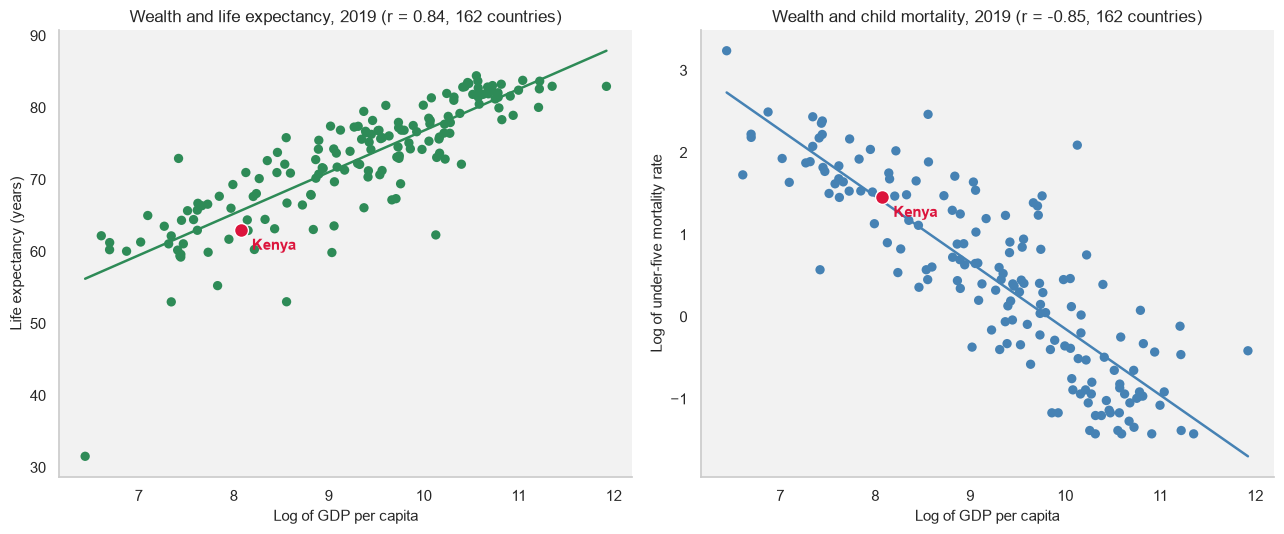

In [6]:
# clear scatter plots: one solid dot per country, for one year
def scatter(ax, data, x, y, xlabel, ylabel, title, color="seagreen", fit="line"):
    # I draw one solid dot per country on a light grey background
    ax.set_facecolor("#f2f2f2")
    ax.scatter(data[x], data[y], s=45, color=color, edgecolor="none", zorder=3)

    # I add a thin trend line
    if fit == "line":
        slope, intercept = np.polyfit(data[x], data[y], 1)
        xs = np.linspace(data[x].min(), data[x].max(), 100)
        ax.plot(xs, slope * xs + intercept, color=color, linewidth=1.8, zorder=2)

    # I highlight Kenya in red and label it
    k = data[data["Entity"] == "Kenya"]
    if len(k) > 0:
        ax.scatter(k[x], k[y], s=100, color="crimson", edgecolor="white", zorder=4)
        ax.annotate("Kenya", (k[x].iloc[0], k[y].iloc[0]), textcoords="offset points",
                    xytext=(8, -14), color="crimson", fontsize=11, fontweight="bold")

    r = np.corrcoef(data[x], data[y])[0, 1]
    ax.set_title(f"{title} (r = {r:.2f}, {len(data)} countries)", fontsize=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# I use one year so each country is one dot
year = 2019
one_year = df[df["Year"] == year]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter(axes[0], one_year, "log_gdp", "life_exp",
        "Log of GDP per capita", "Life expectancy (years)", f"Wealth and life expectancy, {year}")
scatter(axes[1], one_year, "log_gdp", "log_child_mort",
        "Log of GDP per capita", "Log of under-five mortality rate", f"Wealth and child mortality, {year}", color="steelblue")
plt.tight_layout()
plt.show()

### scatter plots, 2019

Each dot is one country in 2019, so the dots and no repeated countries. The red dot is Kenya.

**Life expectancy:** richer countries live longer (r = 0.84). Kenya sits about 2.7 years below the trend line for its income, so its life expectancy is a little lower than expected.

**Child mortality:** I use the log of child mortality because the raw relationship is curved and a straight line would predict impossible negative values. Richer countries have lower child mortality (r = -0.85). Kenya sits on the trend line, so its child mortality is about what its income would predict.

**What this adds:** these charts show the same pattern as the all-years cloud, but each country appears only once, so the points are independent and the chart is easy to read.

In [7]:
df.head()

,Entity,Code,Year,life_exp,gdp_pc,child_mort,log_gdp,log_child_mort,decade,gdp_group,gdp_quartile,mort_group,period
0,Afghanistan,AFG,1957,31.3451,1253.0,36.82,7.133296,3.606041,1950,Below median GDP,Q1 poorest,High child mortality,Before 2000
1,Afghanistan,AFG,1958,31.8400,1298.0,36.21,7.168580,3.589335,1950,Below median GDP,Q1 poorest,High child mortality,Before 2000
2,Afghanistan,AFG,1959,32.3365,1307.0,35.64,7.175490,3.573469,1950,Below median GDP,Q1 poorest,High child mortality,Before 2000
3,Afghanistan,AFG,1960,32.7987,1326.0,35.06,7.189922,3.557061,1960,Below median GDP,Q1 poorest,High child mortality,Before 2000
4,Afghanistan,AFG,1961,33.2910,1309.0,34.52,7.177019,3.541539,1960,Below median GDP,Q1 poorest,High child mortality,Before 2000


In [8]:
df.tail()

,Entity,Code,Year,life_exp,gdp_pc,child_mort,log_gdp,log_child_mort,decade,gdp_group,gdp_quartile,mort_group,period
10424,Zimbabwe,ZWE,2018,60.9055,1900.1992,5.63,7.549714,1.728109,2010,Below median GDP,Q1 poorest,High child mortality,2000 and after
10425,Zimbabwe,ZWE,2019,61.0603,1753.0244,5.86,7.469098,1.768150,2010,Below median GDP,Q1 poorest,High child mortality,2000 and after
10426,Zimbabwe,ZWE,2020,61.5300,1585.9728,6.17,7.368953,1.819699,2020,Below median GDP,Q1 poorest,High child mortality,2000 and after
10427,Zimbabwe,ZWE,2021,60.1347,1687.2532,6.24,7.430857,1.830980,2020,Below median GDP,Q1 poorest,High child mortality,2000 and after
10428,Zimbabwe,ZWE,2022,62.3601,1703.5294,6.40,7.440457,1.856298,2020,Below median GDP,Q1 poorest,High child mortality,2000 and after


In [9]:
df.sample()

,Entity,Code,Year,life_exp,gdp_pc,child_mort,log_gdp,log_child_mort,decade,gdp_group,gdp_quartile,mort_group,period
4959,Kazakhstan,KAZ,1987,65.9965,11389.0,5.5,9.340403,1.704748,1980,Above median GDP,Q3,High child mortality,Before 2000


In [10]:
scatter(axes[0], one_year, "log_gdp", "life_exp", "Log of GDP per capita", "Life Expectancy", "Life Expectancy vs. GDP")
scatter(axes[1], one_year, "log_gdp", "child_mort", "Log of GDP per capita", "Child Mortality", "Child Mortality vs. GDP")

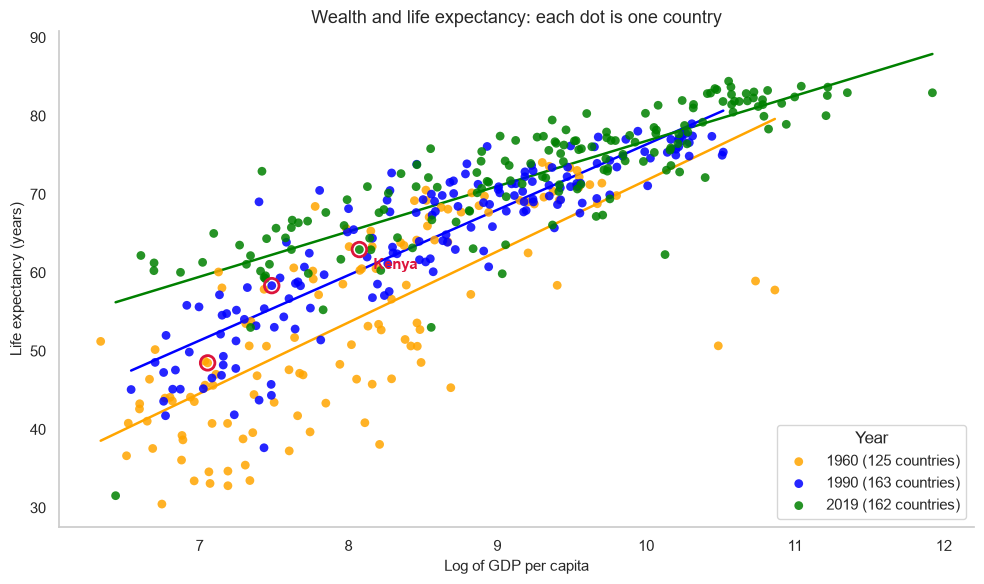

1960: at a log GDP of 8 the trend line gives 53.6 years, at a log GDP of 10 it gives 71.8 years
1990: at a log GDP of 8 the trend line gives 59.7 years, at a log GDP of 10 it gives 76.3 years
2019: at a log GDP of 8 the trend line gives 65.2 years, at a log GDP of 10 it gives 76.8 years


In [11]:
# a clear version of the hexbin chart: same axes, but solid dots, one dot per country, three years in different colours

years = [1960, 1990, 2019]                     # I can change these to any years from 1950 to 2022
colors = ["orange", "blue", "green"]    # orange, blue, green

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("white")

for yr, col in zip(years, colors):
    d = df[df["Year"] == yr]
    # I draw one solid dot per country for this year
    ax.scatter(d["log_gdp"], d["life_exp"], s=40, color=col, edgecolor="none", alpha=0.85,
               label=f"{yr} ({len(d)} countries)", zorder=3)
    # I add a thin trend line for this year in the same colour
    slope, intercept = np.polyfit(d["log_gdp"], d["life_exp"], 1)
    xs = np.linspace(d["log_gdp"].min(), d["log_gdp"].max(), 100)
    ax.plot(xs, slope * xs + intercept, color=col, linewidth=1.8, zorder=2)

# I highlight Kenya in each year with a red ring and label the latest year
for yr in years:
    k = df[(df["Entity"] == "Kenya") & (df["Year"] == yr)]
    ax.scatter(k["log_gdp"], k["life_exp"], s=110, facecolor="none", edgecolor="crimson", linewidth=2, zorder=4)
last = df[(df["Entity"] == "Kenya") & (df["Year"] == years[-1])]
ax.annotate("Kenya", (last["log_gdp"].iloc[0], last["life_exp"].iloc[0]), textcoords="offset points",
            xytext=(10, -14), color="crimson", fontsize=11, fontweight="bold")

ax.set_title("Wealth and life expectancy: each dot is one country", fontsize=13)
ax.set_xlabel("Log of GDP per capita", fontsize=11)
ax.set_ylabel("Life expectancy (years)", fontsize=11)
ax.legend(title="Year", loc="lower right")
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# I print the gap between the years: how much longer do people live at the same income?
for yr in years:
    d = df[df["Year"] == yr]
    s, i = np.polyfit(d["log_gdp"], d["life_exp"], 1)
    print(f"{yr}: at a log GDP of 8 the trend line gives {s*8+i:.1f} years, at a log GDP of 10 it gives {s*10+i:.1f} years")

### Cwealth and life expectancy in 1960, 1990 and 2019

**Why I made it:** my question is whether richer countries have longer life expectancy, and whether that link has held over time. This chart compares three years on the same axes.

**How to read it:**
- Each dot is one country. The colour shows the year: orange is 1960 (125 countries), blue is 1990 (163) and green is 2019 (162). The line of each colour is the trend for that year. The red rings mark Kenya.
- The horizontal axis is the log of GDP per capita. A value of 8 is about 3,000 international dollars and 10 is about 22,000. Each step to the right multiplies income by about 2.7.
- The vertical axis is life expectancy: the number of years a person is expected to live. It is not a calendar year.

**What it shows:**
1. **The link holds in every year.** Richer countries live longer in 1960 (r = 0.74), 1990 (r = 0.89) and 2019 (r = 0.84).
2. **The lines move upward over time.** At a log GDP of 8, the trend gives about 54 years in 1960, 60 in 1990 and 65 in 2019, so people at the same income live longer now.
3. **The gap narrows at high income.** At a log GDP of 10 the trend gives about 72, 76 and 77 years, so the lines nearly meet. This supports my hypothesis that the gains flatten.

**Caution:** this shows a pattern, not a cause.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

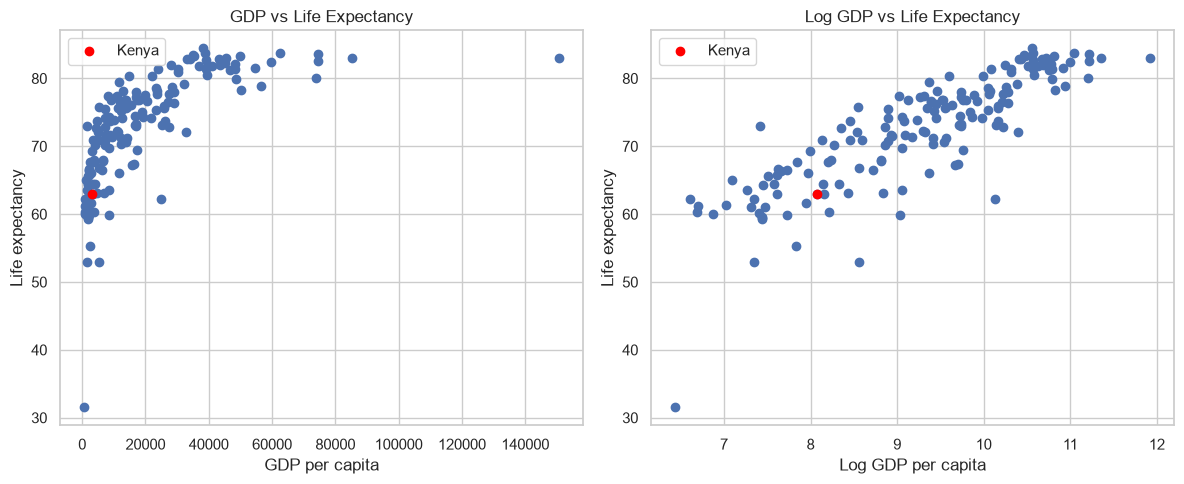

Average Life Expectancy by Income Group:
gdp_pc
Under 2,000      60.4
2,000–5,000      65.8
5,000–10,000     69.9
10,000–20,000    74.5
20,000–40,000    78.5
Over 40,000      81.8
Name: life_exp, dtype: float64


In [13]:
# GDP and Life Expectancy Analysis - 2019

# Select one year
year = 2019
one_year = df[df["Year"] == year]

# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw GDP vs Life Expectancy
axes[0].scatter(one_year["gdp_pc"], one_year["life_exp"])
axes[0].set_xlabel("GDP per capita")
axes[0].set_ylabel("Life expectancy")
axes[0].set_title("GDP vs Life Expectancy")

# Log GDP vs Life Expectancy
axes[1].scatter(one_year["log_gdp"], one_year["life_exp"])
axes[1].set_xlabel("Log GDP per capita")
axes[1].set_ylabel("Life expectancy")
axes[1].set_title("Log GDP vs Life Expectancy")

# Highlight Kenya
kenya = one_year[one_year["Entity"] == "Kenya"]

axes[0].scatter(kenya["gdp_pc"], kenya["life_exp"], color="red", label="Kenya")
axes[1].scatter(kenya["log_gdp"], kenya["life_exp"], color="red", label="Kenya")

axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.show()


# Divide countries into income groups
bands = pd.cut(
    one_year["gdp_pc"],
    [0, 2000, 5000, 10000, 20000, 40000, 1000000000],
    labels=[
        "Under 2,000",
        "2,000–5,000",
        "5,000–10,000",
        "10,000–20,000",
        "20,000–40,000",
        "Over 40,000"
    ]
)

# Calculate average life expectancy
band_table = one_year.groupby(
    bands, observed=True
)["life_exp"].mean().round(1)

print("Average Life Expectancy by Income Group:")
print(band_table)

### raw GDP vs log GDP and life expectancy, 2019

**What it shows:** the same 162 countries in 2019, drawn two ways. Each dot is one country, and the red dot is Kenya.

**Left panel, raw GDP in dollars (orange)**
- Life expectancy rises steeply at low income and then flattens. The orange curve climbs fast up to about 20,000 dollars and is almost flat above about 40,000 dollars, so extra income adds fewer years at high income levels.
- Most countries are crowded on the left, because GDP is strongly right-skewed and a few very rich countries stretch the axis.
- Kenya sits near the low-income end, at about 3,200 dollars and 62.9 years.
- The lone dot at the bottom, at about 31 years, is the Central African Republic. The data does not explain it.

**Right panel, log GDP (green)**
- Taking the log spreads out the crowded left side and pulls in the far right, so the pattern becomes close to a straight line.
- Kenya sits about 2.7 years below the trend line, so its life expectancy is a little lower than other countries with a similar income.

**Why the correlation differs (0.66 vs 0.84):** it is the same countries and the same life expectancy values. The correlation r measures how well the dots fit a straight line. On the raw scale the pattern is curved, so a straight line fits poorly (r = 0.66). After the log it is nearly straight, so r is higher (r = 0.84). Only the spacing changed, not the data. This is why I use log GDP in my correlations and tests.

**The flattening in numbers (2019)**

| GDP per capita | Countries | Average life expectancy | Gain over the band below |
|---|---|---|---|
| under 2,000 | 20 | 60.4 years | |
| 2,000 to 5,000 | 24 | 65.8 years | +5.4 |
| 5,000 to 10,000 | 25 | 69.9 years | +4.1 |
| 10,000 to 20,000 | 38 | 74.5 years | +4.6 |
| 20,000 to 40,000 | 35 | 78.5 years | +4.0 |
| over 40,000 | 20 | 81.8 years | +3.3 |

The gains are generally smaller as income rises, and the last one is the smallest. The bands also get wider in dollars, so the same step up in income buys fewer years at the top. The gains are not perfectly steady (+4.1 then +4.6), so I describe the trend as "generally" smaller, not "always".

**What this means for my question:** the chart supports my hypothesis that richer countries live longer, but the gains flatten at high income.

**Caution:** this is one year, and it shows a pattern, not what would happen to a country whose income grew. Rich and poor countries also differ in other ways, such as health systems and education, and the data cannot separate those.


CORRELATION INSIDE EACH DECADE


,decade,rows,"r (log GDP, life exp)","r (log GDP, child mort)"
0,1950,904,0.816,-0.769
1,1960,1201,0.779,-0.731
2,1970,1359,0.807,-0.772
3,1980,1600,0.871,-0.839
4,1990,1628,0.879,-0.843
5,2000,1630,0.830,-0.797
6,2010,1621,0.835,-0.783
7,2020,486,0.827,-0.712


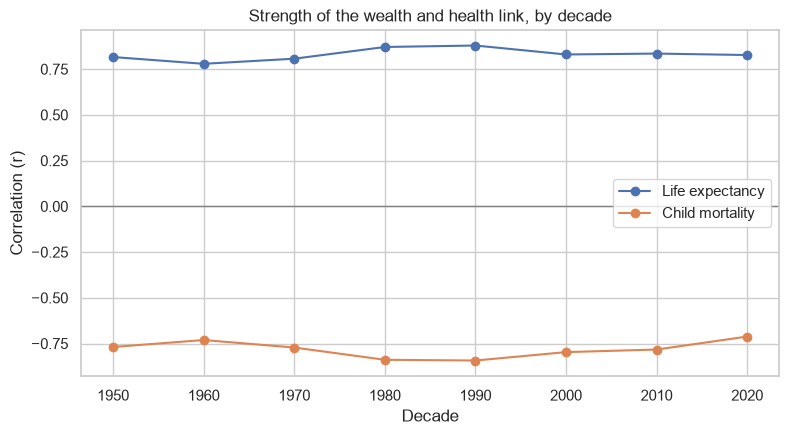

In [14]:
# checking whether the link has held over time by repeating the correlation inside each decade
by_decade = []
for dec, g in df.groupby("decade"):
    by_decade.append({
        "decade": dec,
        "rows": len(g),
        "r (log GDP, life exp)": round(stats.pearsonr(g["log_gdp"], g["life_exp"])[0], 3),
        "r (log GDP, child mort)": round(stats.pearsonr(g["log_gdp"], g["child_mort"])[0], 3),
    })
by_decade = pd.DataFrame(by_decade)
print("\nCORRELATION INSIDE EACH DECADE")
display(by_decade)

plt.figure(figsize=(9, 4.5))
plt.plot(by_decade["decade"], by_decade["r (log GDP, life exp)"], marker="o", label="Life expectancy")
plt.plot(by_decade["decade"], by_decade["r (log GDP, child mort)"], marker="o", label="Child mortality")
plt.axhline(0, color="gray", linewidth=1)
plt.title("Strength of the wealth and health link, by decade")
plt.xlabel("Decade")
plt.ylabel("Correlation (r)")
plt.legend()
plt.show()


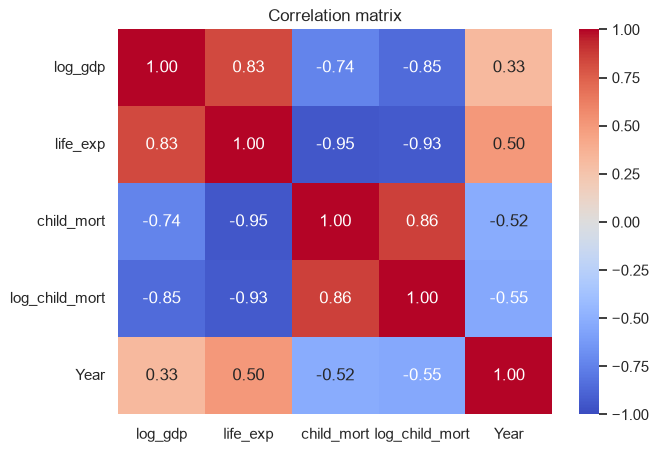

In [15]:
# showing all the correlations together in one heatmap
cols = ["log_gdp", "life_exp", "child_mort", "log_child_mort", "Year"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

In [16]:
# lookingg at Kenya on its own as my local example

kenya = df[df["Entity"] == "Kenya"]
print("\nKENYA")
print("Rows:", len(kenya))
print("r (log GDP, life exp):", round(stats.pearsonr(kenya["log_gdp"], kenya["life_exp"])[0], 3))
print("r (log GDP, child mort):", round(stats.pearsonr(kenya["log_gdp"], kenya["child_mort"])[0], 3))


KENYA
Rows: 73
r (log GDP, life exp): 0.817
r (log GDP, child mort): -0.892


## What the correlations show

**Question:** does higher GDP per capita go with longer life expectancy and lower child mortality?

**Life expectancy:** the Pearson correlation between log GDP and life expectancy is 0.83 (Spearman 0.86). Richer country-years tend to have longer life expectancy, and log GDP explains about 69% of the variation.

**Child mortality:** the correlation between log GDP and child mortality is -0.74 (Spearman -0.86), and -0.85 against the log of child mortality. Richer country-years tend to have lower child mortality. The sign is negative because as GDP rises, child mortality falls.

**Why log GDP:** raw GDP is strongly right-skewed. The raw GDP correlation is lower (0.62) than its Spearman (0.86), which shows the relationship is curved: extra income adds less life expectancy at high income levels. This supports my hypothesis that the gains flatten.

**Has the link held since 1950?** yes. Inside every decade the correlation with life expectancy stays between 0.78 and 0.88, and with child mortality between -0.71 and -0.84.

**Important caution:** a strong correlation does not show that wealth causes better health. Health can also help an economy grow, and other things such as education, medicine, and peace may drive both. Also, the same country appears in many years, so the rows are not independent, and the p-values (all below 0.001) look more impressive than they should. The correlation values themselves are the more reliable result.